# Análisis Exploratorio de Datos (EDA)
Dataset simulado de crédito: `dataset_simulado_90_10.csv`

**Secciones**
1. Carga y vista general
2. Calidad de datos (nulos, duplicados, tipos)
3. Estadísticos descriptivos
4. Análisis univariado (numéricas y categóricas)
5. Variable objetivo (`mora`)
6. Análisis bivariado respecto a `mora`
7. Correlaciones
8. Outliers
9. Chequeos de coherencia

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RUTA = "dataset_simulado_90_10.csv"
TARGET = "mora"

## 1. Carga y vista general

In [26]:
df = pd.read_csv(RUTA)
print("Filas, columnas:", df.shape)
df.head(10)

Filas, columnas: (8399, 13)


,mora,atraso,vivienda,edad,ingreso,nivel_educ,genero,estado_civil,sector_economico,exp_otras_entidades,forma_pago,num_cuotas,tasa_interes
0,1,235,FAMILIAR,30,"3,500.000",UNIVERSITARIA,F,CONVIVIENTE,EDUCATIVO,1,MENSUAL,9,41.410
1,0,18,FAMILIAR,32,900.000,TECNICA,M,CASADO,EDUCATIVO,0,SEMANAL,24,43.970
2,0,0,FAMILIAR,26,"2,400.000",UNIVERSITARIA,F,SOLTERO,EDUCATIVO,0,MENSUAL,16,36.610
3,0,0,FAMILIAR,36,"2,700.000",TECNICA,F,CASADO,EDUCATIVO,0,QUINCENAL,13,29.470
4,1,0,FAMILIAR,46,"3,100.000",TECNICA,M,CONVIVIENTE,COMERCIO,0,MENSUAL,22,39.510
5,0,22,FAMILIAR,25,"2,200.000",UNIVERSITARIA,F,CONVIVIENTE,AGROPECUARIO,0,MENSUAL,26,38.940
6,0,9,FAMILIAR,30,"2,100.000",UNIVERSITARIA,F,CONVIVIENTE,COMERCIO,0,QUINCENAL,10,36.430
7,0,8,PROPIA,55,"5,593.210",TECNICA,F,CASADO,MANUFACTURA,1,SEMANAL,21,27.490
8,0,2,FAMILIAR,30,"2,000.000",UNIVERSITARIA,M,CONVIVIENTE,SERVICIOS,0,MENSUAL,11,45.170
9,0,0,FAMILIAR,31,"3,800.000",TECNICA,M,CONVIVIENTE,COMERCIO,0,QUINCENAL,10,34.930


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8399 entries, 0 to 8398
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   mora                 8399 non-null   int64  
 1   atraso               8399 non-null   int64  
 2   vivienda             8399 non-null   object 
 3   edad                 8399 non-null   int64  
 4   ingreso              8399 non-null   float64
 5   nivel_educ           8399 non-null   object 
 6   genero               8399 non-null   object 
 7   estado_civil         8399 non-null   object 
 8   sector_economico     8399 non-null   object 
 9   exp_otras_entidades  8399 non-null   int64  
 10  forma_pago           8399 non-null   object 
 11  num_cuotas           8399 non-null   int64  
 12  tasa_interes         8399 non-null   float64
dtypes: float64(2), int64(5), object(6)
memory usage: 853.2+ KB


## 2. Calidad de datos

In [28]:
# Nulos
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "% nulos": df.isna().mean() * 100
}).sort_values("nulos", ascending=False)
nulos

,nulos,% nulos
mora,0,0.000
atraso,0,0.000
vivienda,0,0.000
edad,0,0.000
ingreso,0,0.000
nivel_educ,0,0.000
genero,0,0.000
estado_civil,0,0.000
sector_economico,0,0.000
exp_otras_entidades,0,0.000


In [29]:
# Duplicados
print("Filas duplicadas:", df.duplicated().sum())

Filas duplicadas: 0


In [30]:
# Clasificación de variables
num_cols = df.select_dtypes(include="number").columns.drop(TARGET).tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print("Numéricas :", num_cols)
print("Categóricas:", cat_cols)

# Numéricas con pocos valores únicos (posibles binarias / discretas)
df[num_cols].nunique().sort_values()

Numéricas : ['atraso', 'edad', 'ingreso', 'exp_otras_entidades', 'num_cuotas', 'tasa_interes']
Categóricas: ['vivienda', 'nivel_educ', 'genero', 'estado_civil', 'sector_economico', 'forma_pago']


exp_otras_entidades       2
edad                     56
atraso                   63
num_cuotas               85
ingreso                2293
tasa_interes           2741
dtype: int64

## 3. Estadísticos descriptivos

In [31]:
df[num_cols + [TARGET]].describe().T

,count,mean,std,min,25%,50%,75%,max
atraso,"8,399.000",4.463,14.271,0.000,0.000,0.000,2.000,245.000
edad,"8,399.000",36.399,9.826,20.000,29.000,34.000,42.000,85.000
ingreso,"8,399.000","4,350.407","5,367.059",123.700,"1,366.670","2,400.000","4,900.000","30,000.000"
exp_otras_entidades,"8,399.000",0.454,0.498,0.000,0.000,0.000,1.000,1.000
num_cuotas,"8,399.000",22.012,16.123,6.000,12.000,17.000,26.000,90.000
tasa_interes,"8,399.000",33.750,7.274,18.000,28.725,33.600,38.680,60.880
mora,"8,399.000",0.100,0.300,0.000,0.000,0.000,0.000,1.000


In [32]:
df[cat_cols].describe().T

,count,unique,top,freq
vivienda,8399,3,FAMILIAR,5853
nivel_educ,8399,4,UNIVERSITARIA,4802
genero,8399,2,M,4415
estado_civil,8399,5,CASADO,2723
sector_economico,8399,9,COMERCIO,2510
forma_pago,8399,4,MENSUAL,3859


## 4. Análisis univariado

### 4.1 Numéricas

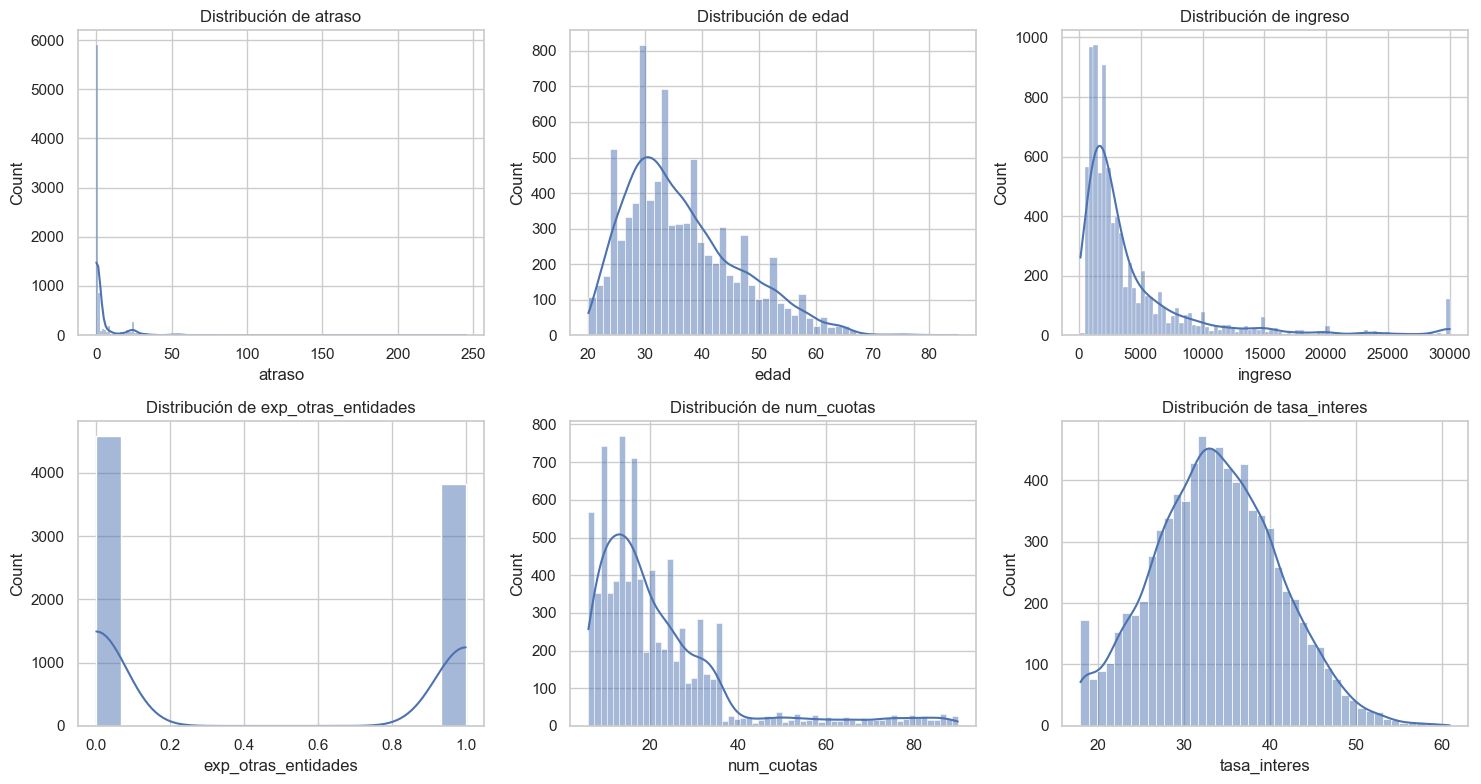

In [33]:
n = len(num_cols)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = np.array(axes).ravel()
for ax, c in zip(axes, num_cols):
    sns.histplot(df[c].dropna(), kde=True, ax=ax)
    ax.set_title(f"Distribución de {c}")
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [34]:
# Asimetría y curtosis
pd.DataFrame({
    "skew": df[num_cols].skew(),
    "kurtosis": df[num_cols].kurt()
})

,skew,kurtosis
atraso,10.002,147.887
edad,0.786,0.158
ingreso,2.885,9.162
exp_otras_entidades,0.184,-1.967
num_cuotas,2.149,5.025
tasa_interes,0.138,-0.151


### 4.2 Categóricas

In [35]:
for c in cat_cols:
    print(f"--- {c} ---")
    print(pd.DataFrame({
        "n": df[c].value_counts(dropna=False),
        "%": df[c].value_counts(normalize=True, dropna=False) * 100
    }))
    print()

--- vivienda ---
              n      %
vivienda              
FAMILIAR   5853 69.687
PROPIA     2381 28.349
ALQUILADA   165  1.965

--- nivel_educ ---
                  n      %
nivel_educ                
UNIVERSITARIA  4802 57.173
TECNICA        3288 39.148
SECUNDARIA      267  3.179
SIN EDUCACION    42  0.500

--- genero ---
           n      %
genero             
M       4415 52.566
F       3984 47.434

--- estado_civil ---
                 n      %
estado_civil             
CASADO        2723 32.421
CONVIVIENTE   2683 31.944
SOLTERO       2281 27.158
DIVORCIADO     523  6.227
VIUDO          189  2.250

--- sector_economico ---
                     n      %
sector_economico             
COMERCIO          2510 29.885
SERVICIOS         1480 17.621
TRANSPORTES       1005 11.966
AGROPECUARIO       859 10.227
CONSTRUCCION       729  8.680
EDUCATIVO          651  7.751
MANUFACTURA        591  7.037
SALUD              325  3.870
OTROS              249  2.965

--- forma_pago ---
          

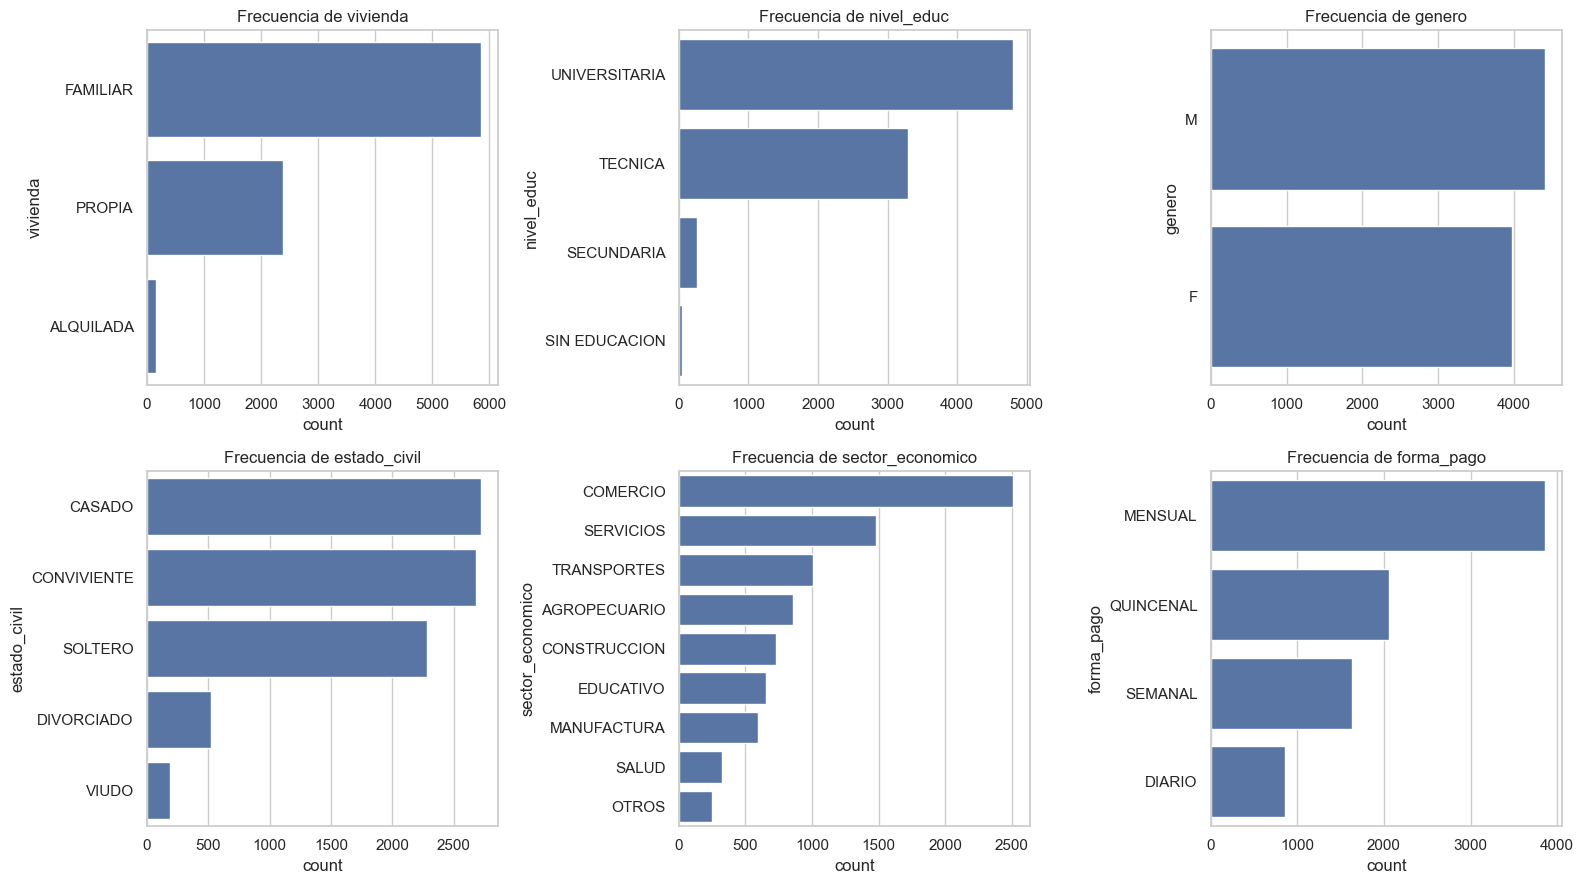

In [36]:
n = len(cat_cols)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.5 * nrows))
axes = np.array(axes).ravel()
for ax, c in zip(axes, cat_cols):
    order = df[c].value_counts().index
    sns.countplot(data=df, y=c, order=order, ax=ax)
    ax.set_title(f"Frecuencia de {c}")
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Variable objetivo: `mora`

         n      %
mora             
0     7559 89.999
1      840 10.001


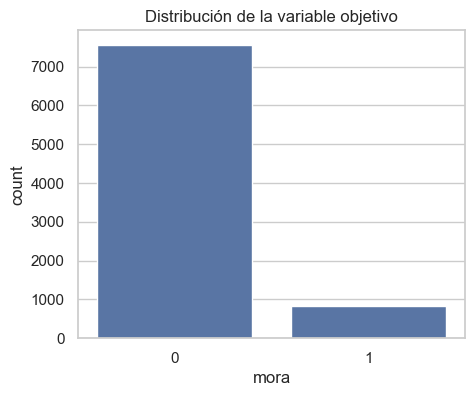

In [37]:
conteo = df[TARGET].value_counts(dropna=False)
prop = df[TARGET].value_counts(normalize=True, dropna=False) * 100
print(pd.DataFrame({"n": conteo, "%": prop}))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x=TARGET, ax=ax)
ax.set_title("Distribución de la variable objetivo")
plt.show()

## 6. Análisis bivariado respecto a `mora`

### 6.1 Numéricas vs mora

In [38]:
df.groupby(TARGET)[num_cols].agg(["mean", "median", "std"]).T

mora                               0         1
atraso              mean       4.462     4.469
                    median     0.000     0.000
                    std       14.449    12.566
edad                mean      36.543    35.107
                    median    35.000    33.000
                    std        9.882     9.214
ingreso             mean   4,493.193 3,065.506
                    median 2,500.000 2,000.000
                    std    5,518.708 3,483.083
exp_otras_entidades mean       0.462     0.386
                    median     0.000     0.000
                    std        0.499     0.487
num_cuotas          mean      21.991    22.200
                    median    17.000    17.000
                    std       16.064    16.652
tasa_interes        mean      32.798    42.315
                    median    32.850    42.735
                    std        6.695     6.647

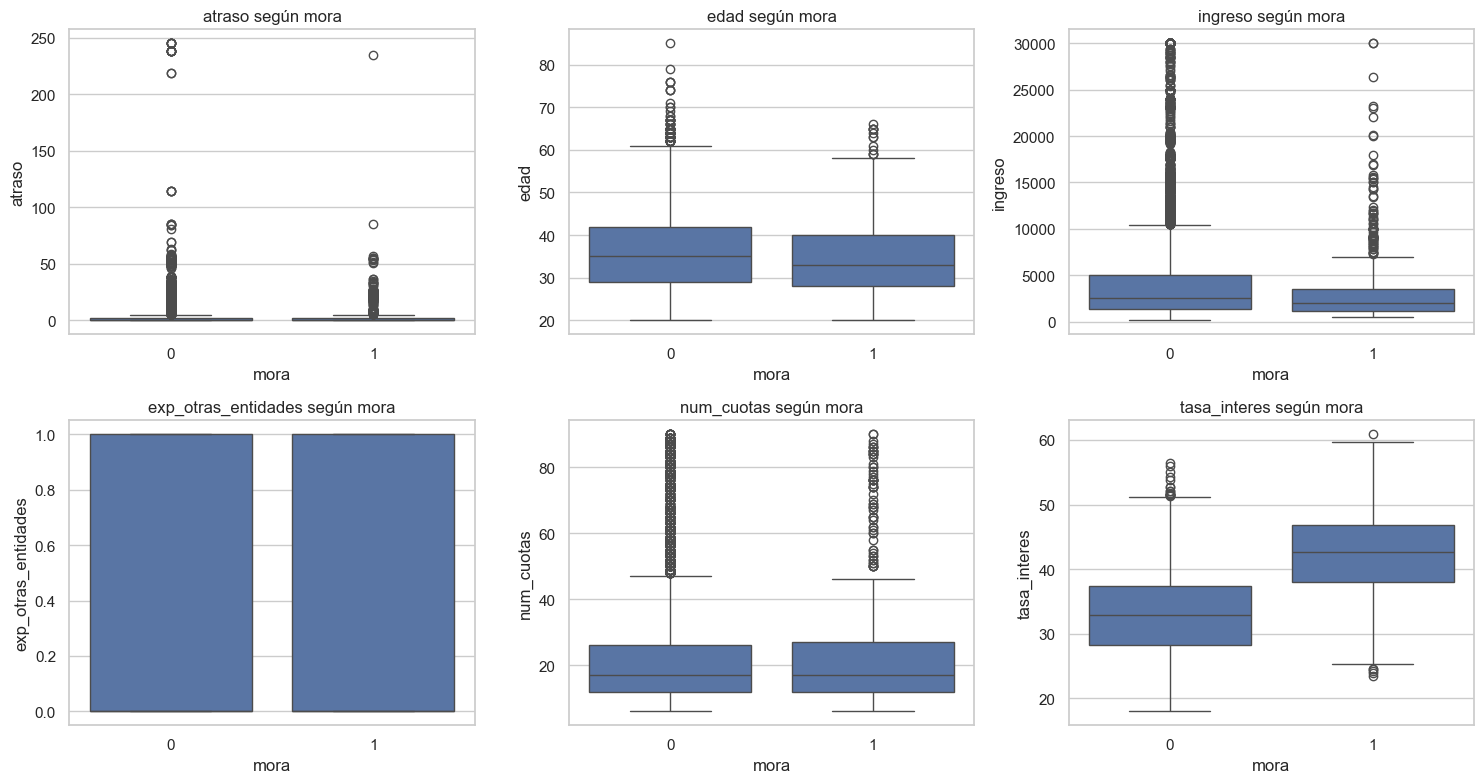

In [39]:
n = len(num_cols)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = np.array(axes).ravel()
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=df, x=TARGET, y=c, ax=ax)
    ax.set_title(f"{c} según mora")
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 6.2 Categóricas vs mora (tasa de mora por categoría)

In [40]:
for c in cat_cols:
    tabla = (df.groupby(c)[TARGET]
               .agg(n="count", tasa_mora="mean")
               .sort_values("tasa_mora", ascending=False))
    tabla["tasa_mora"] = tabla["tasa_mora"] * 100
    print(f"--- {c} (tasa de mora en %) ---")
    print(tabla, "\n")

--- vivienda (tasa de mora en %) ---
              n  tasa_mora
vivienda                  
ALQUILADA   165     20.000
FAMILIAR   5853     10.507
PROPIA     2381      8.064 

--- nivel_educ (tasa de mora en %) ---
                  n  tasa_mora
nivel_educ                    
SECUNDARIA      267     14.607
TECNICA        3288     13.990
SIN EDUCACION    42      9.524
UNIVERSITARIA  4802      7.018 

--- genero (tasa de mora en %) ---
           n  tasa_mora
genero                 
M       4415     10.306
F       3984      9.664 

--- estado_civil (tasa de mora en %) ---
                 n  tasa_mora
estado_civil                 
VIUDO          189     11.111
DIVORCIADO     523     10.707
SOLTERO       2281     10.478
CASADO        2723      9.916
CONVIVIENTE   2683      9.467 

--- sector_economico (tasa de mora en %) ---
                     n  tasa_mora
sector_economico                 
CONSTRUCCION       729     12.071
TRANSPORTES       1005     10.249
COMERCIO          2510     10.23

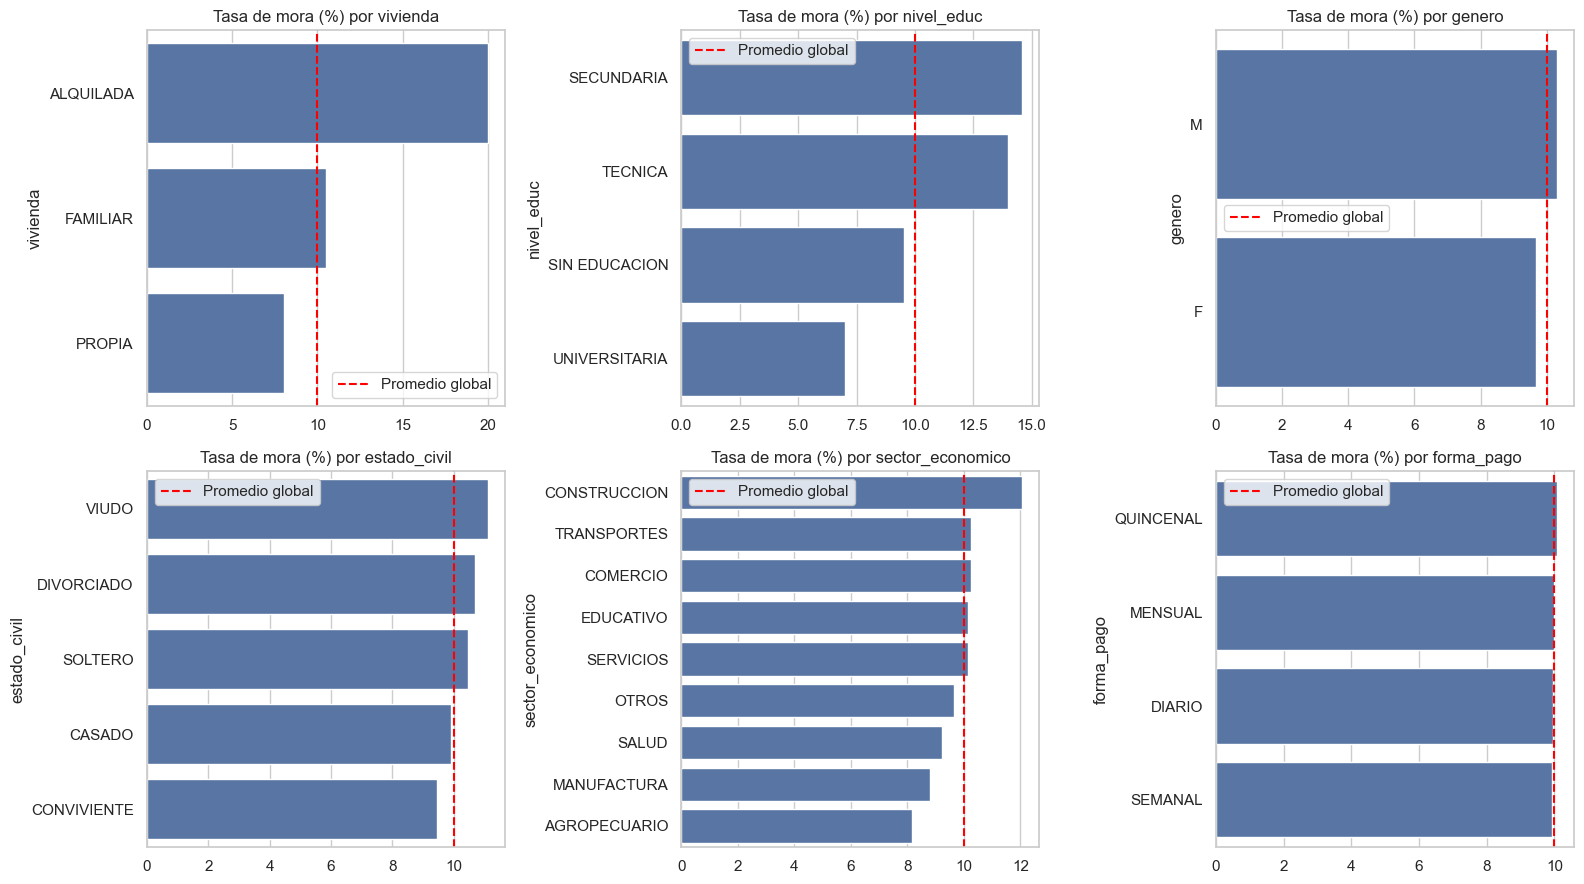

In [41]:
n = len(cat_cols)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.5 * nrows))
axes = np.array(axes).ravel()
for ax, c in zip(axes, cat_cols):
    t = df.groupby(c)[TARGET].mean().sort_values(ascending=False) * 100
    sns.barplot(x=t.values, y=t.index, ax=ax)
    ax.axvline(df[TARGET].mean() * 100, color="red", ls="--", label="Promedio global")
    ax.set_title(f"Tasa de mora (%) por {c}")
    ax.legend()
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Correlaciones

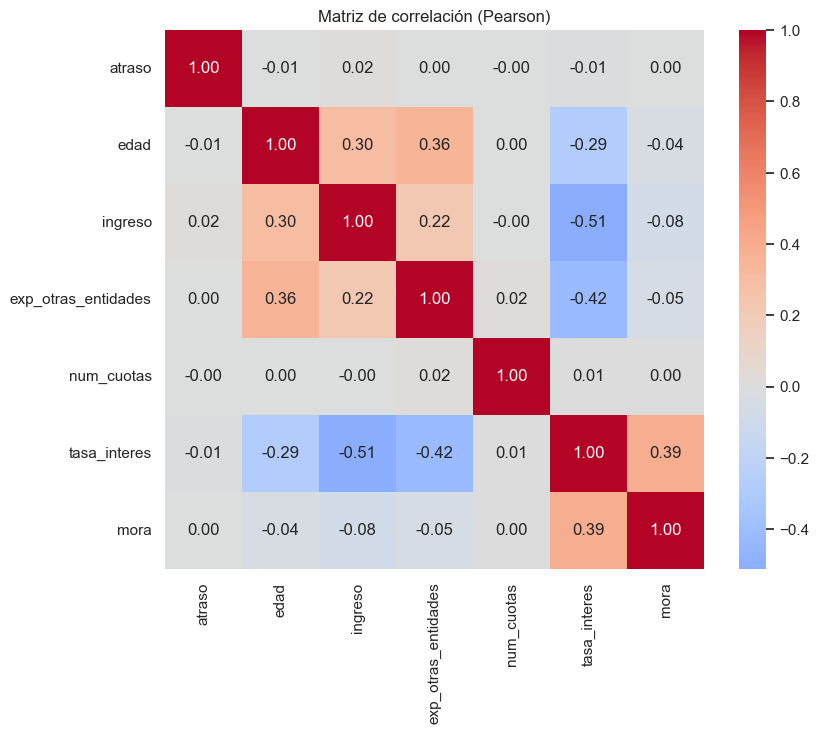

In [42]:
corr = df[num_cols + [TARGET]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Matriz de correlación (Pearson)")
plt.show()

In [43]:
# Correlación de cada variable con mora
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)

tasa_interes           0.393
ingreso               -0.080
exp_otras_entidades   -0.046
edad                  -0.044
num_cuotas             0.004
atraso                 0.000
Name: mora, dtype: float64

## 8. Outliers (regla del IQR)

In [44]:
res = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[c] < low) | (df[c] > high)).sum()
    res.append([c, low, high, n_out, n_out / len(df) * 100])
pd.DataFrame(res, columns=["variable", "límite_inf", "límite_sup", "n_outliers", "% outliers"])

,variable,límite_inf,límite_sup,n_outliers,% outliers
0,atraso,-3.000,5.000,1431,17.038
1,edad,9.500,61.500,120,1.429
2,ingreso,"-3,933.325","10,199.995",777,9.251
3,exp_otras_entidades,-1.500,2.500,0,0.000
4,num_cuotas,-9.000,47.000,618,7.358
5,tasa_interes,13.793,53.612,34,0.405


## 9. Chequeos de coherencia

In [45]:
# 9.1 Relación entre atraso (días) y mora
print(pd.crosstab(df["atraso"] > 0, df[TARGET], rownames=["atraso > 0"], colnames=["mora"]))
print()
print(df.groupby(TARGET)["atraso"].describe())

mora           0    1
atraso > 0           
False       4741  483
True        2818  357

         count  mean    std   min   25%   50%   75%     max
mora                                                       
0    7,559.000 4.462 14.449 0.000 0.000 0.000 2.000 245.000
1      840.000 4.469 12.566 0.000 0.000 0.000 2.000 235.000


In [46]:
# 9.2 Número de cuotas según forma de pago
df.groupby("forma_pago")["num_cuotas"].describe()

,count,mean,std,min,25%,50%,75%,max
forma_pago,,,,,,,,
DIARIO,854.000,60.718,17.672,30.000,46.000,60.000,77.000,90.000
MENSUAL,"3,859.000",20.900,8.947,6.000,13.000,21.000,29.000,36.000
QUINCENAL,"2,054.000",12.044,3.734,6.000,9.000,12.000,15.000,18.000
SEMANAL,"1,632.000",16.931,5.464,8.000,12.000,17.000,22.000,26.000


In [47]:
# 9.3 Experiencia en otras entidades vs edad
print(df.groupby("exp_otras_entidades")["edad"].describe())

                        count   mean    std    min    25%    50%    75%    max
exp_otras_entidades                                                           
0                   4,584.000 33.207  8.080 20.000 27.000 32.000 38.000 71.000
1                   3,815.000 40.235 10.352 20.000 32.000 39.000 48.000 85.000


In [48]:
# 9.4 Valores imposibles o sospechosos
chequeos = {
    "edad < 18": (df["edad"] < 18).sum(),
    "edad > 80": (df["edad"] > 80).sum(),
    "ingreso <= 0": (df["ingreso"] <= 0).sum(),
    "atraso < 0": (df["atraso"] < 0).sum(),
    "num_cuotas <= 0": (df["num_cuotas"] <= 0).sum(),
    "tasa_interes <= 0": (df["tasa_interes"] <= 0).sum(),
}
pd.Series(chequeos, name="n_casos")

edad < 18            0
edad > 80            1
ingreso <= 0         0
atraso < 0           0
num_cuotas <= 0      0
tasa_interes <= 0    0
Name: n_casos, dtype: int64

## Resumen para pasar a la limpieza
Copia los resultados de las celdas (en especial las secciones 2, 3, 5, 8 y 9) para decidir:
- tratamiento de nulos,
- manejo de outliers,
- codificación de categóricas,
- balanceo de la variable objetivo.